# Лабораторная работа № 2. Определение и развёртывание OLAP-куба

**Вариант 7 — Stack Overflow Developer Survey 2011–2022.** Цель — построить многомерное представление ответов, выполнить срезы и агрегацию и исследовать динамику по годам.

Источники — CSV за 2011–2021 годы из [архива варианта на Kaggle](https://www.kaggle.com/datasets/yasirabdaali/stack-overflow-developer-survey-20112022) и [исходный CSV Stack Overflow за 2022 год](https://github.com/StackExchange/Survey/tree/main/packages/archive/2022). Последний заменяет повреждённый CSV за 2022 год в архиве Kaggle.

Запускайте сверху вниз в ядре **R**. Нужны `tibble`, `dplyr` и `rolap`. При необходимости выполните в R `install.packages(c("tibble", "dplyr", "rolap"))`. Для работы с локальными источниками укажите полный путь к ZIP в `ITAIOD_SURVEY_ZIP` и к официальному CSV 2022 года в `ITAIOD_SURVEY_CSV`. Без этих переменных файлы загружаются из источников во временную папку.

## 1. Импорт и согласование данных

В CSV каждая запись — один ответ конкретной волны. Год получаем из имени файла. Географическое поле в ранних выпусках имеет развёрнутое название, в поздних — `Country` или `country`. В выпусках 2011–2014 первая строка после заголовка содержит техническую разметку `Response`. В файле 2015 года техническая строка находится перед заголовком. Эти строки пропускаются.

В каждом году сохраняются заполненные и пустые географические ответы. Пустые значения получают категорию «Не указано». Несколько явно эквивалентных исторических названий приведены к общему виду. Укрупнённые ответы вроде `Other Europe` остаются отдельными уровнями.

In [1]:
library(tibble)
library(dplyr)
library(rolap)

# Возвращает существующий локальный файл либо загружает исходник во временный файл.
resolve_input <- function(path, url, extension) {
  if (nzchar(path)) {
    if (!file.exists(path)) {
      stop("Входной файл не найден: ", path)
    }
    return(path)
  }
  destination <- tempfile(fileext = extension)
  status <- download.file(url, destination, mode = "wb", quiet = TRUE)
  if (status != 0L) {
    stop("Не удалось загрузить ", url)
  }
  destination
}

# Читает заголовок либо одно поле из файла CSV внутри архива.
read_zip_csv <- function(archive, member, year, column_types = NA, rows = -1L) {
  connection <- unz(archive, member, open = "rt")
  on.exit(close(connection))
  read.csv(
    connection, nrows = rows, skip = as.integer(year == 2015L),
    colClasses = column_types, row.names = NULL, check.names = FALSE,
    encoding = if (year <= 2012L) "latin1" else "UTF-8",
    na.strings = c("", "NA")
  )
}

# Извлекает страну или регион для каждого ответа заданного года.
read_historical_wave <- function(archive, member, year) {
  headers <- names(read_zip_csv(archive, member, year, rows = 0L))
  country_column <- grep(
    "^(country|what country.*live in\\?)$", headers, ignore.case = TRUE
  )
  if (length(country_column) != 1L) {
    stop("Не найдено однозначное географическое поле в ", member)
  }

  column_types <- rep("NULL", length(headers))
  column_types[country_column] <- "character"
  locations <- read_zip_csv(archive, member, year, column_types)[[1L]]
  if (year <= 2014L) {
    if (!identical(locations[1L], "Response")) {
      stop("Неожиданная структура раннего CSV: ", member)
    }
    locations <- locations[-1L]
  }
  tibble(year = year, place = locations)
}

# Составляет таблицу ответов по годам из архивных и официальных исходников.
read_survey_waves <- function(zip_path, csv_path) {
  zip_url <- paste0(
    "https://www.kaggle.com/api/v1/datasets/download/yasirabdaali/",
    "stack-overflow-developer-survey-20112022?datasetVersionNumber=1"
  )
  csv_url <- paste0(
    "https://media.githubusercontent.com/media/StackExchange/Survey/",
    "main/packages/archive/2022/results.csv"
  )
  previous_options <- options(timeout = max(300L, getOption("timeout")))
  on.exit(options(previous_options), add = TRUE)
  archive <- resolve_input(zip_path, zip_url, ".zip")
  if (!nzchar(zip_path)) {
    on.exit(unlink(archive), add = TRUE)
  }
  latest <- resolve_input(csv_path, csv_url, ".csv")
  if (!nzchar(csv_path)) {
    on.exit(unlink(latest), add = TRUE)
  }

  members <- unzip(archive, list = TRUE)$Name
  members <- members[grepl("^20(1[1-9]|2[01]).*\\.csv$", basename(members))]
  years <- as.integer(substr(basename(members), 1L, 4L))
  if (length(years) != 11L || !setequal(years, 2011:2021)) {
    stop("В ZIP нужна ровно одна таблица CSV для каждого года с 2011 по 2021.")
  }
  historical <- bind_rows(Map(
    function(member, year) read_historical_wave(archive, member, year),
    members, years
  ))

  headers <- names(read.csv(latest, nrows = 0L, check.names = FALSE))
  if (!all(c("ResponseId", "Country") %in% headers)) {
    stop("Официальный CSV должен содержать ResponseId и Country.")
  }
  latest_responses <- read.csv(
    latest, check.names = FALSE, encoding = "UTF-8",
    colClasses = ifelse(headers %in% c("ResponseId", "Country"), "character", "NULL"),
    na.strings = c("", "NA")
  )
  if (anyNA(latest_responses$ResponseId) || anyDuplicated(latest_responses$ResponseId)) {
    stop("Идентификаторы ответов за 2022 год должны быть заполнены и уникальны.")
  }
  bind_rows(historical, tibble(year = 2022L, place = latest_responses$Country))
}

responses_raw <- read_survey_waves(
  Sys.getenv("ITAIOD_SURVEY_ZIP"), Sys.getenv("ITAIOD_SURVEY_CSV")
)
print(count(responses_raw, year, name = "rows"), n = Inf)


Attaching package: 'dplyr'




The following objects are masked from 'package:stats':

    filter, lag




The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




# A tibble: 12 × 2
    year  rows
   <int> <int>
 1  2011  2813
 2  2012  6243
 3  2013  9742
 4  2014  7643
 5  2015 26086
 6  2016 56030
 7  2017 51392
 8  2018 98855
 9  2019 88883
10  2020 64461
11  2021 83439
12  2022 73268


In [2]:
place_names <- c(
  "United States of America" = "United States",
  "United Kingdom of Great Britain and Northern Ireland" = "United Kingdom",
  "Czech Republic" = "Czechia",
  "Russian Federation" = "Russia",
  "Viet Nam" = "Vietnam"
)
responses <- responses_raw |>
  mutate(
    place = trimws(place),
    place = coalesce(na_if(place, ""), "Не указано"),
    place = recode(place, !!!place_names),
    decade = paste0(year %/% 10L * 10L, "-е")
  )
geography_quality <- responses |>
  group_by(year) |>
  summarise(
    responses = n(),
    missing_place = sum(place == "Не указано"),
    share_missing = round(100 * missing_place / responses, 2),
    .groups = "drop"
  )
print(geography_quality, n = Inf)

# A tibble: 12 × 4
    year responses missing_place share_missing
   <int>     <int>         <int>         <dbl>
 1  2011      2813             0          0   
 2  2012      6243             0          0   
 3  2013      9742             1          0.01
 4  2014      7643             0          0   
 5  2015     26086             0          0   
 6  2016     56030           502          0.9 
 7  2017     51392             0          0   
 8  2018     98855           412          0.42
 9  2019     88883           132          0.15
10  2020     64461           389          0.6 
11  2021     83439             0          0   
12  2022     73268          1497          2.04


## 2. Схема «звезда»

Зерно таблицы фактов — сочетание волны и ответа о месте проживания. Мера `responses` содержит количество анкет для сочетания и агрегируется суммой. Измерение времени включает иерархию «десятилетие → год». Измерение географии содержит страну, регион или служебный уровень для пропусков. Схема задаётся средствами `rolap`, как в разделе 2.5 методических указаний. [Документация пакета](https://josesamos.github.io/rolap/reference/star_database.html).

In [3]:
fact_input <- count(responses, decade, year, place, name = "responses")
survey_schema <- star_schema() |>
  define_facts(name = "survey", measures = "responses", agg_functions = "SUM") |>
  define_dimension(name = "wave", attributes = c("decade", "year")) |>
  define_dimension(name = "geography", attributes = "place")
survey_db <- star_database(survey_schema, fact_input)
star_tables <- as_tibble_list(survey_db)

print(tibble(
  table = names(star_tables),
  rows = vapply(star_tables, nrow, integer(1L)),
  columns = vapply(star_tables, ncol, integer(1L))
))
print(lapply(star_tables, head, n = 4L))
stopifnot(sum(star_tables$survey$responses) == nrow(responses))

# A tibble: 3 × 3
  table      rows columns
  <chr>     <int>   <int>
1 wave         12       3
2 geography   281       2
3 survey     1600       4


$wave
# A tibble: 4 × 3
  wave_key decade year 
     <int> <chr>  <chr>
1        1 2010-е 2011 
2        2 2010-е 2012 
3        3 2010-е 2013 
4        4 2010-е 2014 

$geography
# A tibble: 4 × 2
  geography_key place        
          <int> <chr>        
1             1 Afghanistan  
2             2 Africa       
3             3 Aland Islands
4             4 Albania      

$survey
# A tibble: 4 × 4
  wave_key geography_key responses nrow_agg
     <int>         <int>     <int>    <int>
1        1             2        43        1
2        1            16        29        1
3        1            17       112        1
4        1            47       156        1



## 3. Операции над кубом

- **Roll-up** суммирует ответы по годам или десятилетиям, убирая измерение географии.
- **Drill-down** раскрывает десятилетие 2020-х по отдельным волнам до 2022 года.
- **Slice** фиксирует 2022 год и показывает географию ответов.
- **Dice** выбирает три волны и три страны. В повёрнутой таблице годы идут по строкам, страны — по столбцам.

Для географических долей знаменатель — все ответы выбранного года, включая строки без указанного места.

In [4]:
year_query <- survey_db |>
  star_query() |>
  select_dimension(name = "wave", attributes = "year") |>
  select_fact(name = "survey", measures = "responses")
year_tables <- as_single_tibble_list(run_query(survey_db, year_query))
year_totals <- year_tables$survey |>
  select(year, responses) |>
  mutate(year = as.integer(year)) |>
  arrange(year)

decade_query <- survey_db |>
  star_query() |>
  select_dimension(name = "wave", attributes = "decade") |>
  select_fact(name = "survey", measures = "responses")
decade_tables <- as_single_tibble_list(run_query(survey_db, decade_query))
decade_totals <- decade_tables$survey |>
  select(decade, responses) |>
  arrange(decade)

print(decade_totals)
print(year_totals, n = Inf)
print(filter(year_totals, year >= 2020L))
stopifnot(
  sum(decade_totals$responses) == nrow(responses),
  identical(as.numeric(year_totals$responses), as.numeric(geography_quality$responses))
)

# A tibble: 2 × 2
  decade responses
  <chr>      <int>
1 2010-е    347687
2 2020-е    221168


# A tibble: 12 × 2
    year responses
   <int>     <int>
 1  2011      2813
 2  2012      6243
 3  2013      9742
 4  2014      7643
 5  2015     26086
 6  2016     56030
 7  2017     51392
 8  2018     98855
 9  2019     88883
10  2020     64461
11  2021     83439
12  2022     73268


# A tibble: 3 × 2
   year responses
  <int>     <int>
1  2020     64461
2  2021     83439
3  2022     73268


In [5]:
slice_query <- survey_db |>
  star_query() |>
  select_dimension(name = "wave", attributes = "year") |>
  select_dimension(name = "geography", attributes = "place") |>
  select_fact(name = "survey", measures = "responses") |>
  filter_dimension(name = "wave", year == "2022")
latest_tables <- as_single_tibble_list(run_query(survey_db, slice_query))
latest_slice <- latest_tables$survey

top_places <- latest_slice |>
  mutate(share_pct = 100 * responses / sum(responses)) |>
  filter(place != "Не указано") |>
  slice_max(responses, n = 5L, with_ties = FALSE) |>
  select(place, responses, share_pct)
print(top_places)

dice_query <- survey_db |>
  star_query() |>
  select_dimension(name = "wave", attributes = "year") |>
  select_dimension(name = "geography", attributes = "place") |>
  select_fact(name = "survey", measures = "responses") |>
  filter_dimension(name = "wave", year %in% c("2020", "2021", "2022")) |>
  filter_dimension(name = "geography", place %in% c("United States", "India", "Germany"))
recent_tables <- as_single_tibble_list(run_query(survey_db, dice_query))
recent_slice <- recent_tables$survey
print(xtabs(responses ~ year + place, data = recent_slice))

# A tibble: 5 × 3
  place          responses share_pct
  <chr>              <int>     <dbl>
1 United States      13543     18.5 
2 India               6639      9.06
3 Germany             5395      7.36
4 United Kingdom      4190      5.72
5 Canada              2490      3.40


      place
year   Germany India United States
  2020    3890  8403         12469
  2021    5625 10511         15288
  2022    5395  6639         13543


## 4. Динамика ответов и выводы

График показывает размер каждой волны. Точки обозначают наблюдаемые годы.

Куб хранит 568855 ответов. Наибольшая волна — 2018 год, 98855 ответов.
В 2022 году получено 73268 ответов, изменение относительно 2021 года: -12.2%.
Лидер географического среза за 2022 год — United States: 13543 ответов (18.5% всей волны).


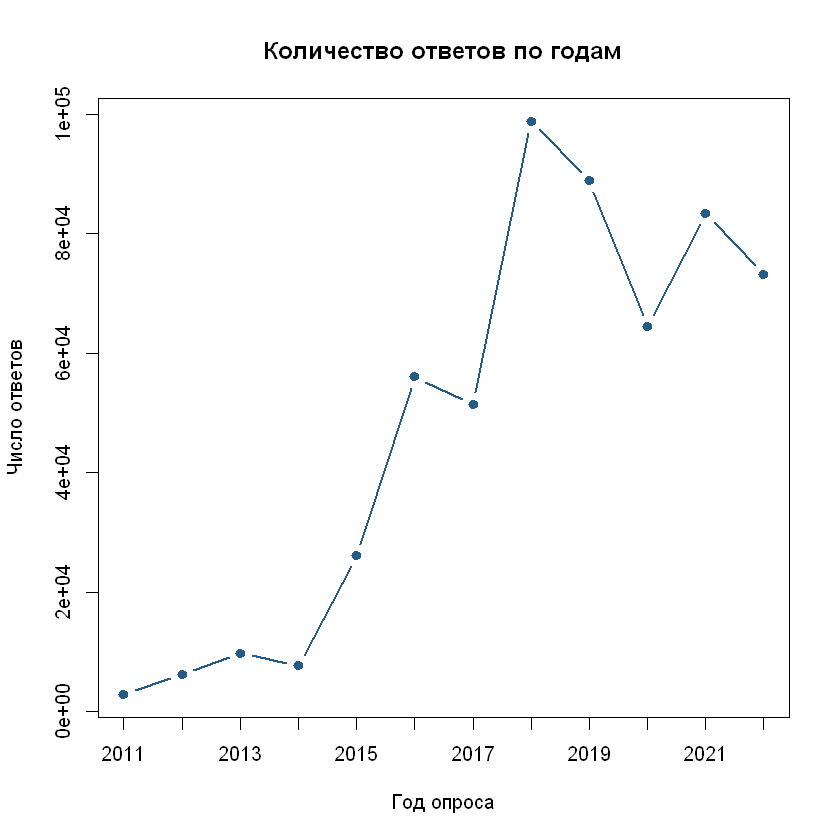

In [6]:
plot(
  responses ~ year, data = year_totals, type = "b",
  xaxt = "n", pch = 19, col = "#245B87", lwd = 2,
  main = "Количество ответов по годам",
  xlab = "Год опроса", ylab = "Число ответов"
)
axis(1, at = year_totals$year)

peak_wave <- slice_max(year_totals, responses, n = 1L, with_ties = FALSE)
latest_total <- filter(year_totals, year == 2022L)$responses
previous_total <- filter(year_totals, year == 2021L)$responses
relative_change <- 100 * (latest_total / previous_total - 1)
cat(sprintf(
  paste0(
    "Куб хранит %d ответов. Наибольшая волна — %d год, %d ответов.\n",
    "В 2022 году получено %d ответов, изменение относительно 2021 года: %+.1f%%.\n",
    "Лидер географического среза за 2022 год — %s: %d ответов (%.1f%% всей волны).\n"
  ),
  sum(year_totals$responses), peak_wave$year, peak_wave$responses,
  latest_total, relative_change, top_places$place[1L], top_places$responses[1L],
  top_places$share_pct[1L]
))

Размер волны зависит от сбора ответов и состава аудитории. Динамика куба отражает участие в опросе. В географическом срезе крупные категории из ранних анкет могут объединять несколько стран, поэтому сравнения отдельных стран между волнами следует читать с учётом изменения вариантов ответа.